# Decision Trees

# Task-1

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [2]:
# Load the dataset
df = pd.read_csv("loan_approval.csv")

In [3]:
df.shape

(3000, 7)

In [4]:
df.value_counts()

age  income  credit_score  debt_ratio  num_loans  employed  approved
24   114096  688           0.757       0          0         0           1
55   63205   724           0.169       3          1         1           1
49   60412   843           0.161       0          0         1           1
40   95669   759           0.206       0          1         1           1
     115122  558           0.335       2          0         1           1
                                                                       ..
48   193295  537           0.431       0          1         1           1
34   65520   822           0.318       5          0         1           1
36   74163   628           0.186       1          0         1           1
40   66585   786           0.435       4          0         1           1
50   87728   602           0.442       5          0         0           1
Name: count, Length: 3000, dtype: int64

In [5]:
# Separate features and target
X = df.drop(columns=["approved"])
y = df["approved"]

In [6]:
# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    random_state=42,
    stratify=y
)

In [7]:
# Create an decision tree
tree = DecisionTreeClassifier(random_state=42)

In [8]:
# Train the model
tree.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [9]:
# Display tree complexity
print("Tree depth:", tree.get_depth())
print("Number of leaves:", tree.get_n_leaves())

# Compare training and testing accuracy
print("Training accuracy:", tree.score(X_train, y_train))
print("Testing accuracy:", tree.score(X_test, y_test))

Tree depth: 22
Number of leaves: 432
Training accuracy: 1.0
Testing accuracy: 0.7293333333333333


# Task-2

In [10]:
# Task 02: Fix the accuracy plot
depths = list(range(1, 16))

In [11]:
# Reset the lists to remove old results
train_accuracies = []
test_accuracies = []

In [12]:
# Train one model for each depth
for d in depths:
    model = DecisionTreeClassifier(
        max_depth=d,
        min_samples_leaf=5,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_accuracies.append(model.score(X_train, y_train))
    test_accuracies.append(model.score(X_test, y_test))

In [13]:
# Check list lengths
print("Number of depths:", len(depths))
print("Training results:", len(train_accuracies))
print("Testing results:", len(test_accuracies))

Number of depths: 15
Training results: 15
Testing results: 15


In [14]:
# Find the best depth
best_depth = depths[np.argmax(test_accuracies)]

print("Best depth:", best_depth)
print("Best test accuracy:", round(max(test_accuracies), 3))

Best depth: 3
Best test accuracy: 0.812


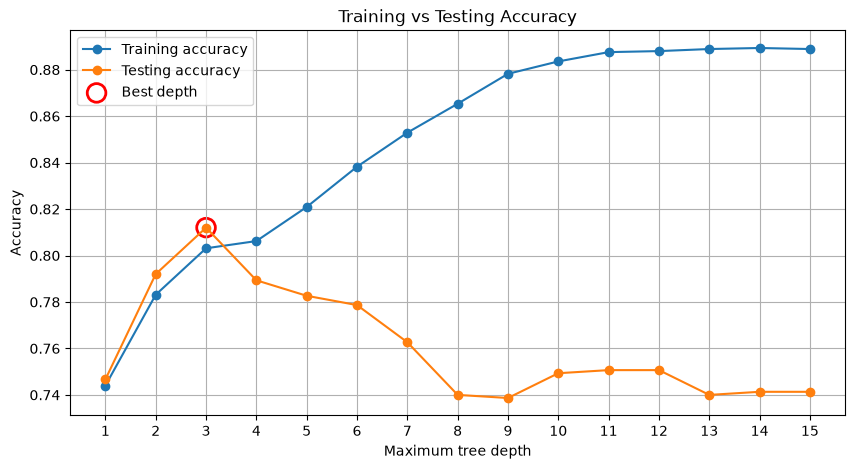

In [15]:
# Plot the results
plt.figure(figsize=(10, 5))

plt.plot(
    depths, train_accuracies,
    marker="o", label="Training accuracy"
)

plt.plot(
    depths, test_accuracies,
    marker="o", label="Testing accuracy"
)

plt.scatter(
    best_depth,
    max(test_accuracies),
    s=180,
    facecolors="none",
    edgecolors="red",
    linewidths=2,
    label="Best depth"
)

plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.title("Training vs Testing Accuracy")
plt.xticks(depths)
plt.legend()
plt.grid(True)
plt.show()

# Task-3

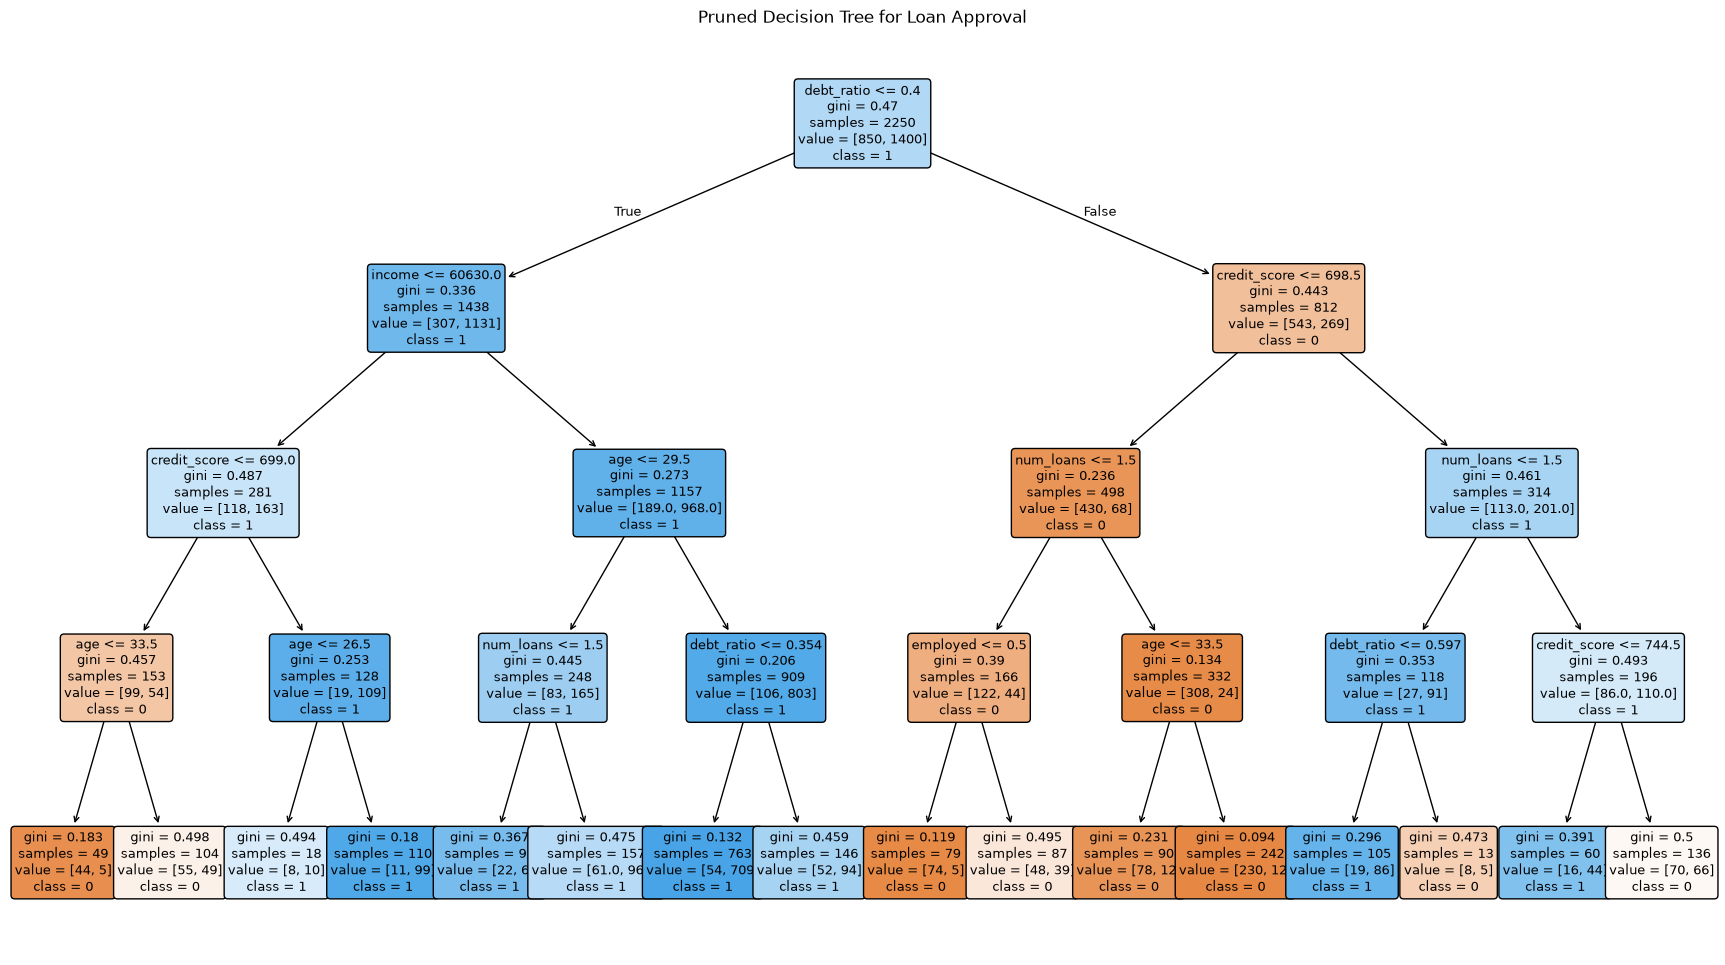

In [16]:
# Create the pruned tree
pruned_tree = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)

pruned_tree.fit(X_train, y_train)

# Draw the tree
plt.figure(figsize=(22, 12))

plot_tree(
    pruned_tree,
    feature_names=list(X.columns),
    class_names=[str(c) for c in pruned_tree.classes_],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Pruned Decision Tree for Loan Approval")
plt.show()


# Task-4

Feature importance ranking:
debt_ratio      0.5112
credit_score    0.2935
age             0.0688
income          0.0636
num_loans       0.0367
employed        0.0262
dtype: float64


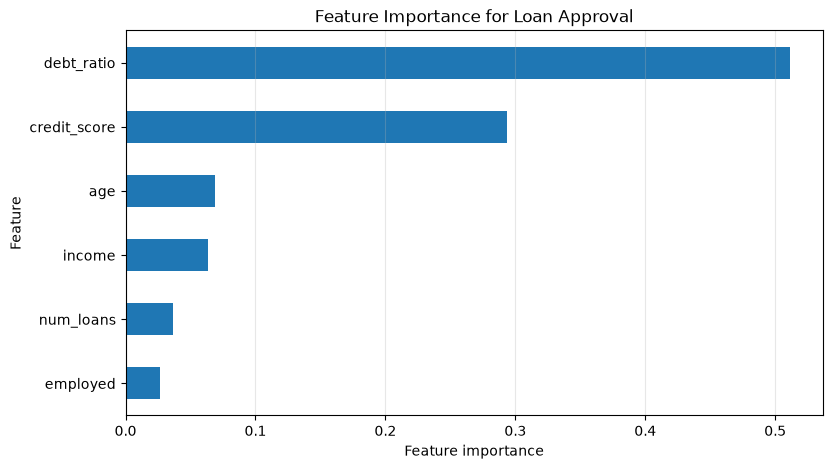

Sum of importance: 1.0


In [17]:
# Get feature importance scores
importances = pd.Series(
    pruned_tree.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature importance ranking:")
print(importances.round(4))

# Plot the ranking
importances.sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Feature Importance for Loan Approval")
plt.grid(axis="x", alpha=0.3)
plt.show()

print("Sum of importance:", round(importances.sum(), 4))


# Task-5

In [18]:

# Create a pipeline with a decision tree
pipe = Pipeline([
    (
        "tree",
        DecisionTreeClassifier(
            min_samples_leaf=5,
            random_state=42
        )
    )
])

cv_scores = {}

In [19]:
# Evaluate each depth using 5-fold cross-validation
for d in range(1, 16):
    pipe.set_params(tree__max_depth=d)

    scores = cross_val_score(
        pipe,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    cv_scores[d] = scores.mean()

In [20]:
# Select depth with highest cross-validation accuracy
best_depth_cv = max(cv_scores, key=cv_scores.get)

print("Best depth by CV:", best_depth_cv)
print("Best CV accuracy:", round(cv_scores[best_depth_cv], 3))

Best depth by CV: 3
Best CV accuracy: 0.79


In [21]:
# Fit the selected model and evaluate on test data once
final_tree = DecisionTreeClassifier(
    max_depth=best_depth_cv,
    min_samples_leaf=5,
    random_state=42
)

final_tree.fit(X_train, y_train)

final_test_accuracy = final_tree.score(X_test, y_test)

print("Final held-out test accuracy:", round(final_test_accuracy, 3))


Final held-out test accuracy: 0.812


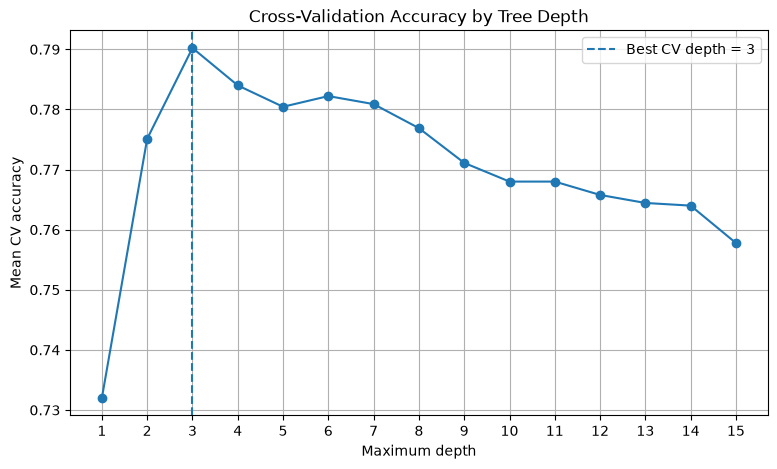

In [22]:
# Display CV scores
plt.figure(figsize=(9, 5))
plt.plot(
    list(cv_scores.keys()),
    list(cv_scores.values()),
    marker="o"
)

plt.axvline(
    best_depth_cv,
    linestyle="--",
    label=f"Best CV depth = {best_depth_cv}"
)

plt.xlabel("Maximum depth")
plt.ylabel("Mean CV accuracy")
plt.title("Cross-Validation Accuracy by Tree Depth")
plt.xticks(range(1, 16))
plt.grid(True)
plt.legend()
plt.show()

# Task-6

In [23]:
# Logistic Regression pipeline
logistic_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

In [24]:
#decision tree
tree_pipe = Pipeline([
    (
        "model",
        DecisionTreeClassifier(
            max_depth=best_depth_cv,
            min_samples_leaf=5,
            random_state=42
        )
    )
])

In [25]:
# Compare cross-validation accuracy
logistic_accuracy = cross_val_score(
    logistic_pipe,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

tree_accuracy = cross_val_score(
    tree_pipe,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

In [26]:
# Compare cross-validation ROC-AUC
logistic_auc = cross_val_score(
    logistic_pipe,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
)

tree_auc = cross_val_score(
    tree_pipe,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
)

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Pruned Decision Tree"],
    "Mean CV Accuracy": [
        logistic_accuracy.mean(),
        tree_accuracy.mean()
    ],
    "Mean CV ROC-AUC": [
        logistic_auc.mean(),
        tree_auc.mean()
    ]
})

print(comparison.round(3))


                  Model  Mean CV Accuracy  Mean CV ROC-AUC
0   Logistic Regression              0.74            0.780
1  Pruned Decision Tree              0.79            0.824


- For this nonlinear dataset, the Decision Tree performs better than Logistic Regression, achieving a higher CV ROC-AUC of 0.824 compared with 0.780.

- The trade-off is that the tree can capture nonlinear relationships and interactions, but it is more complex and can be less stable than the simpler linear model.